## Notebook 4

### On this notebook, will be evaluated the number of missing values after the second webscrapping

In [1]:
import pandas as pd
import numpy as np
import sys
sys.path.insert(1,'..//Classes')
from classes import Worldcup,Team_Players,WorldcupPlayers,WorldcupQuarters,Team_Quarters,Team
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline


In [2]:
df = pd.read_csv('Percentage.csv',header = [0,1],index_col = 0)
df


0  1930 Uruguay                                                1934 Italy  \
1         Teams Players without data Total Players % Missing        Teams   
2       Bolivia                   11            17     64.71    Argentina   
3        Mexico                    8            17     47.06        Egypt   
4      Paraguay                   17            22     77.27      Germany   
5          Peru                    9            23     39.13      Hungary   
6       Romania                    3            20     15.00      Romania   
7           USA                    1            18      5.56  Switzerland   
8    Yugoslavia                    1            17      5.88          USA   
9             0                    0             0      0.00            0   
10            0                    0             0      0.00            0   

0                                                      1938 France  \
1  Players without data Total Players % Missing              Teams   
2                     6            18     33.33               CSSR   
3                     6            16     37.50               Cuba   
4                     2            22      9.09             France   
5                     5            22     22.73            Hungary   
6                     2            22      9.09        Netherlands   
7                     4            22     18.18  Netherlands India   
8                     4            19     21.05             Poland   
9                     0             0      0.00            Romania   
10                    0             0      0.00        Switzerland   

0                        ...    1962 Chile            1970 Mexico  \
1  Players without data  ... Total Players % Missing        Teams   
2                     2  ...            22      4.55  El Salvador   
3                     8  ...            22     18.18      Morocco   
4                     1  ...            22      4.55         Peru   
5                     4  ...            22      4.55            0   
6                     5  ...             0      0.00            0   
7                    14  ...             0      0.00            0   
8                     2  ...             0      0.00            0   
9                     1  ...             0      0.00            0   
10                    3  ...             0      0.00            0   

0                                               1982 Spain  \
1  Players without data Total Players % Missing      Teams   
2                     2            22      9.09     Kuwait   
3                    10            19     52.63          0   
4                     1            22      4.55          0   
5                     0             0      0.00          0   
6                     0             0      0.00          0   
7                     0             0      0.00          0   
8                     0             0      0.00          0   
9                     0             0      0.00          0   
10                    0             0      0.00          0   

0                                                
1  Players without data Total Players % Missing  
2                     7            22     31.82  
3                     0             0      0.00  
4                     0             0      0.00  
5                     0             0      0.00  
6                     0             0      0.00  
7                     0             0      0.00  
8                     0             0      0.00  
9                     0             0      0.00  
10                    0             0      0.00  

[9 rows x 36 columns]

In [3]:
worldcups = df.columns.get_level_values(0).unique().values
worldcups


array(['1930 Uruguay', '1934 Italy', '1938 France', '1950 Brazil',
       '1954 Switzerland', '1958 Sweden', '1962 Chile', '1970 Mexico',
       '1982 Spain'], dtype=object)

Calculating the percentage of missing data

In [4]:
df2 = pd.DataFrame([],columns = worldcups)
lista = []

for worldcup in worldcups:
    total_players = df[worldcup]['Total Players'].sum()
    players_w_missings = df[worldcup]['Players without data'].sum()
    players_w_data = total_players - players_w_missings
    lista.append([worldcup,'Complete',np.around(players_w_data*100/total_players)])
    lista.append([worldcup,'Incomplete',np.around(players_w_missings*100/total_players)])
    
df_before = pd.DataFrame(lista,columns = ['World Cup','Data Type','Percentage'])
df_before.head()


,World Cup,Data Type,Percentage
0,1930 Uruguay,Complete,63.0
1,1930 Uruguay,Incomplete,37.0
2,1934 Italy,Complete,79.0
3,1934 Italy,Incomplete,21.0
4,1938 France,Complete,79.0


In [5]:
wcups_values = []
for worldcup in worldcups:
    missings = 0
    captured = 0
    wcup = WorldcupPlayers(worldcup)
    teams = wcup.get_teams()
    for team in teams:
        tm = wcup.get_players_from_team(team)
        missings_filter = np.logical_and((tm.df()['Month'] == 0),(tm.df()['Name'] != '0'))
        captured_filter = np.logical_and((tm.df()['Month'] != 0),(tm.df()['Name'] != '0'))
        missings += tm.df()['Month'][missings_filter].count()
        captured += tm.df()['Month'][captured_filter].count()
    total = captured + missings
    wcups_values.append([worldcup,"Complete",np.around(captured*100/total)])
    wcups_values.append([worldcup,"Incomplete",np.around(missings*100/total)])

df_after = pd.DataFrame(wcups_values,columns = ['World Cup','Data Type','Percentage'])
df_after
    

,World Cup,Data Type,Percentage
0,1930 Uruguay,Complete,94.0
1,1930 Uruguay,Incomplete,6.0
2,1934 Italy,Complete,96.0
3,1934 Italy,Incomplete,4.0
4,1938 France,Complete,92.0
5,1938 France,Incomplete,8.0
6,1950 Brazil,Complete,96.0
7,1950 Brazil,Incomplete,4.0
8,1954 Switzerland,Complete,99.0
9,1954 Switzerland,Incomplete,1.0


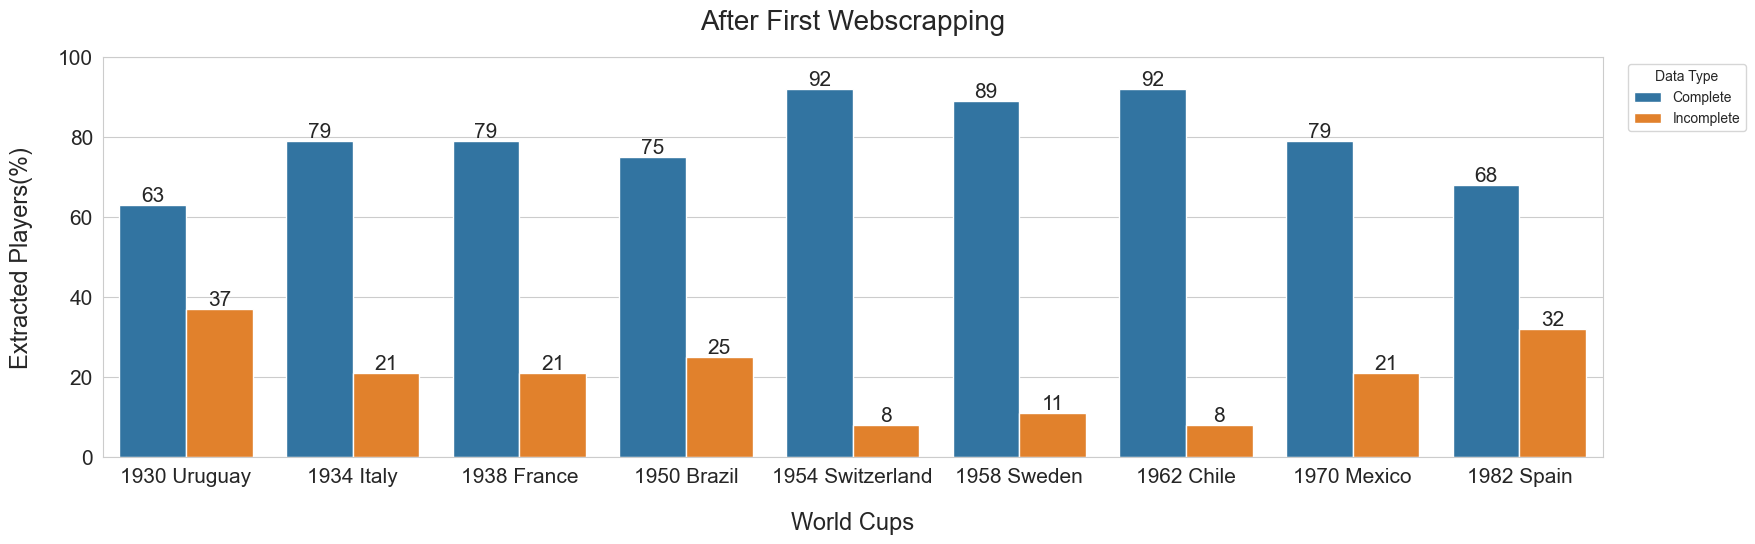

In [6]:
sns.set_style('whitegrid')
fig = plt.figure(figsize = (15,4))
ax = fig.add_axes([0,0,1,1])
ax = sns.barplot(df_before,x = 'World Cup',y = 'Percentage',hue = 'Data Type')
ax.bar_label(ax.containers[0],fontsize = 15)
ax.bar_label(ax.containers[1],fontsize = 15)
ax.set_yticks(np.arange(0,120,20))
ax.set_ylabel('Extracted Players(%)',fontsize = 17,labelpad = 18)
ax.set_xlabel('World Cups',fontsize = 17,labelpad = 18)
ax.tick_params(labelsize = 15)
ax.set_title('After First Webscrapping',fontsize = 20, pad = 20)
ax.legend(bbox_to_anchor=(1.1, 1),loc = 'upper right',title = 'Data Type')

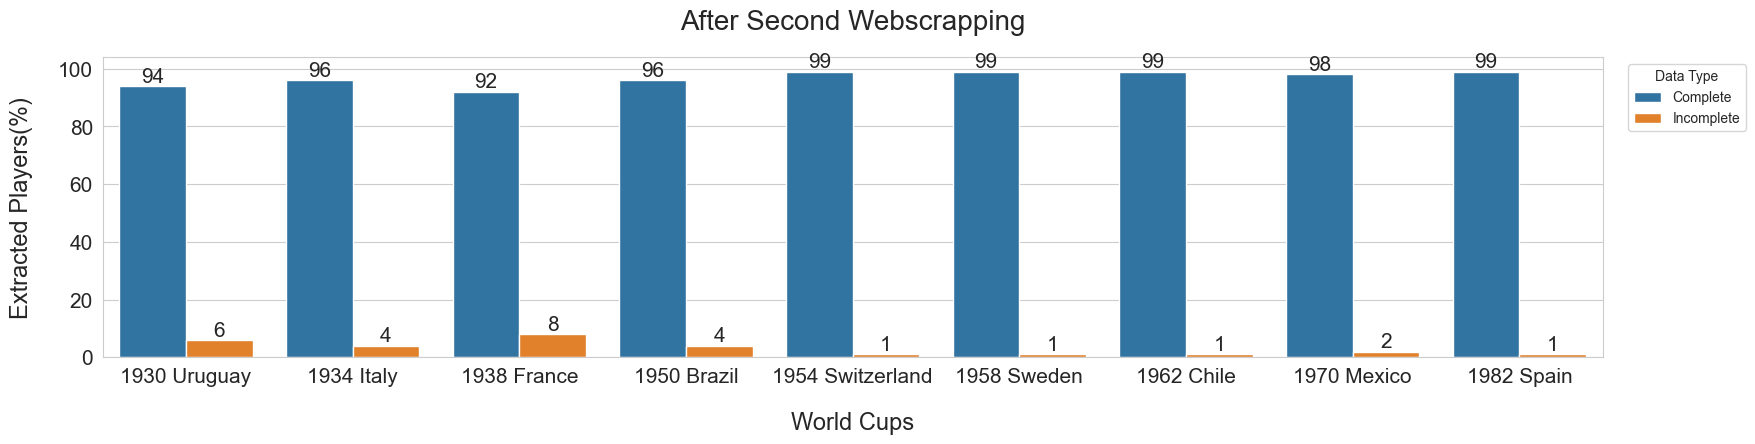

In [7]:
sns.set_style('whitegrid')
fig = plt.figure(figsize = (15,3))
ax = fig.add_axes([0,0,1,1])
ax = sns.barplot(df_after, x = 'World Cup', y = 'Percentage',hue = 'Data Type')
ax.bar_label(ax.containers[0],fontsize = 15)
ax.bar_label(ax.containers[1],fontsize = 15)
ax.set_yticks(np.arange(0,120,20))
ax.set_ylabel('Extracted Players(%)',fontsize = 17,labelpad = 18)
ax.set_xlabel('World Cups',fontsize = 17,labelpad = 18)
ax.tick_params(labelsize = 15)
ax.set_title('After Second Webscrapping',fontsize = 20, pad = 20)
ax.legend(bbox_to_anchor=(1.1, 1),loc = 'upper right',title = 'Data Type')